# VisionMatch AI — 01. Dataset Exploration (EDA)

**Mục tiêu:** hiểu bộ dữ liệu giày *trước* khi xây dựng CLIP embeddings. Notebook **chỉ đọc dữ liệu**, không giải nén, thay ảnh hoặc ghi đè `catalog.csv`.

**Nguồn dataset:** [Cleanlab/footwear-demo trên Hugging Face](https://huggingface.co/datasets/Cleanlab/footwear-demo), tập tin `footwear-demo.zip`. Dự án tải qua `scripts/download_dataset.py`, giải nén vào `data/raw/` và chạy `scripts/prepare_dataset.py` để tạo `data/processed/catalog.csv`.

**Thông tin từ lần chạy trước (chưa phải kết quả notebook này):** ZIP có 915 entries; phát hiện 909 file ảnh; 909 ảnh đọc được; `boot=305`, `sandal=301`, `shoe=303`. Chạy notebook để xác nhận lại trên dữ liệu hiện có.

> **Giới hạn:** tên thư mục được dùng làm *nhãn tạm*; chưa chứng minh mọi nhãn là chính xác. Kiểm tra ảnh trùng bằng hash nếu chạy chỉ xác định trùng file byte-for-byte.

## 0. Data Acquisition – Thu thập dữ liệu


In [ ]:
# %pip install huggingface_hub

In [ ]:
# %run ../scripts/download_dataset.py

## 1. Set Up and Identify the Project Directory

Chọn kernel `.venv` trong VS Code. Nếu cần cài: `python -m pip install ipykernel pandas matplotlib pillow`.

In [1]:
from pathlib import Path
from collections import Counter
from hashlib import sha256
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display

random.seed(42)

# Notebook may run from project root or project/notebooks.
def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    for path in candidates:
        if (path / 'scripts' / 'prepare_dataset.py').exists() and (path / 'data').exists():
            return path
    raise FileNotFoundError('Không tìm thấy project root. Hãy mở VS Code tại thư mục visionmatch-ai.')

ROOT = find_project_root()
RAW = ROOT / 'data' / 'raw'
CATALOG = ROOT / 'data' / 'processed' / 'catalog.csv'
FORMATS = {'.jpg', '.jpeg', '.png', '.webp'}
print('Project root:', ROOT)
print('Raw data exists:', RAW.exists())
print('Catalog exists:', CATALOG.exists())

Project root: d:\SGU(1)\official\visionmatch-ai
Raw data exists: True
Catalog exists: True


## 2. Raw Data Structure
Liệt kê trực tiếp các thư mục và tệp trong `data/raw/`, không dựa vào `catalog.csv`.

In [2]:
if not RAW.is_dir():
    raise FileNotFoundError('Thiếu data/raw — chạy python scripts/download_dataset.py trước.')

# Thư mục, số ảnh trực tiếp và danh sách một số file.
dirs = sorted([p for p in RAW.rglob('*') if p.is_dir()])
print('Số thư mục con:', len(dirs))
for folder in dirs[:25]:
    count = sum(p.is_file() and p.suffix.lower() in FORMATS for p in folder.iterdir())
    print(f'{folder.relative_to(ROOT).as_posix()}/  ({count} ảnh trực tiếp)')

all_files = sorted(p for p in RAW.rglob('*') if p.is_file())
raw_images = [p for p in all_files if p.suffix.lower() in FORMATS]
print('\nTổng files:', len(all_files))
print('Tổng file ảnh:', len(raw_images))
print('10 file đầu:')
for p in raw_images[:10]:
    print(' ', p.relative_to(ROOT).as_posix())

Số thư mục con: 6
data/raw/__MACOSX/  (0 ảnh trực tiếp)
data/raw/__MACOSX/test-zip/  (0 ảnh trực tiếp)
data/raw/test-zip/  (0 ảnh trực tiếp)
data/raw/test-zip/boot/  (305 ảnh trực tiếp)
data/raw/test-zip/sandal/  (301 ảnh trực tiếp)
data/raw/test-zip/shoe/  (303 ảnh trực tiếp)

Tổng files: 912
Tổng file ảnh: 909
10 file đầu:
  data/raw/test-zip/boot/00980.jpg
  data/raw/test-zip/boot/00d04.jpg
  data/raw/test-zip/boot/01a4f.jpg
  data/raw/test-zip/boot/02677.jpg
  data/raw/test-zip/boot/037f2.jpg
  data/raw/test-zip/boot/05898.jpg
  data/raw/test-zip/boot/05fd5.jpg
  data/raw/test-zip/boot/06e0b.jpg
  data/raw/test-zip/boot/06f74.jpg
  data/raw/test-zip/boot/0869b.jpg


## 3. Raw Image Exploration
Kiểm tra phân bố định dạng, nhãn suy ra từ thư mục cha, và kích thước pixel.

In [3]:
raw_rows = []
errors = []
for path in raw_images:
    try:
        with Image.open(path) as im:
            im.load()  # xác nhận giải mã được pixel
            raw_rows.append({
                'image_path': path.relative_to(ROOT).as_posix(),
                'category': path.parent.name,
                'format': im.format or path.suffix.lstrip('.').upper(),
                'width': im.width,
                'height': im.height,
                'file_kb': round(path.stat().st_size / 1024, 2),
            })
    except (OSError, ValueError, UnidentifiedImageError) as exc:
        errors.append({'path': path.relative_to(ROOT).as_posix(), 'error': str(exc)})

raw_df = pd.DataFrame(raw_rows)
print('Ảnh hợp lệ:', len(raw_df), '| Ảnh không đọc được:', len(errors))
if errors:
    display(pd.DataFrame(errors).head(10))
if raw_df.empty:
    raise ValueError('Không có ảnh hợp lệ để khám phá.')
display(raw_df.head(10))
print('Định dạng ảnh:')
display(raw_df['format'].value_counts().rename_axis('format').reset_index(name='count'))
print('Kích thước phổ biến (width × height):')
display(raw_df.groupby(['width','height']).size().sort_values(ascending=False).head(10).rename('count').reset_index())
print('Dung lượng KB:')
display(raw_df['file_kb'].describe().round(2))

Ảnh hợp lệ: 909 | Ảnh không đọc được: 0


,image_path,category,format,width,height,file_kb
0,data/raw/test-zip/boot/00980.jpg,boot,JPEG,136,102,1.89
1,data/raw/test-zip/boot/00d04.jpg,boot,JPEG,136,102,2.40
2,data/raw/test-zip/boot/01a4f.jpg,boot,JPEG,136,102,2.12
3,data/raw/test-zip/boot/02677.jpg,boot,JPEG,136,102,2.47
4,data/raw/test-zip/boot/037f2.jpg,boot,JPEG,136,102,2.96
5,data/raw/test-zip/boot/05898.jpg,boot,JPEG,136,102,3.07
6,data/raw/test-zip/boot/05fd5.jpg,boot,JPEG,136,102,2.39
7,data/raw/test-zip/boot/06e0b.jpg,boot,JPEG,136,102,3.04
8,data/raw/test-zip/boot/06f74.jpg,boot,JPEG,136,102,1.80
9,data/raw/test-zip/boot/0869b.jpg,boot,JPEG,136,102,2.90


Định dạng ảnh:


,format,count
0,JPEG,909


Kích thước phổ biến (width × height):


,width,height,count
0,136,102,908
1,135,102,1


Dung lượng KB:


count    909.00
mean       2.82
std        0.55
min        0.86
25%        2.45
50%        2.83
75%        3.17
max        6.07
Name: file_kb, dtype: float64

## 3.1. Raw Image Exploration - Xem ảnh mẫu từ dữ liệu thô
Mỗi hàng là một category. Dùng *ảnh thô*, không phải ảnh lấy từ CSV. Quan sát nền, góc chụp, kiểu dáng và sự khác nhau giữa nhóm.

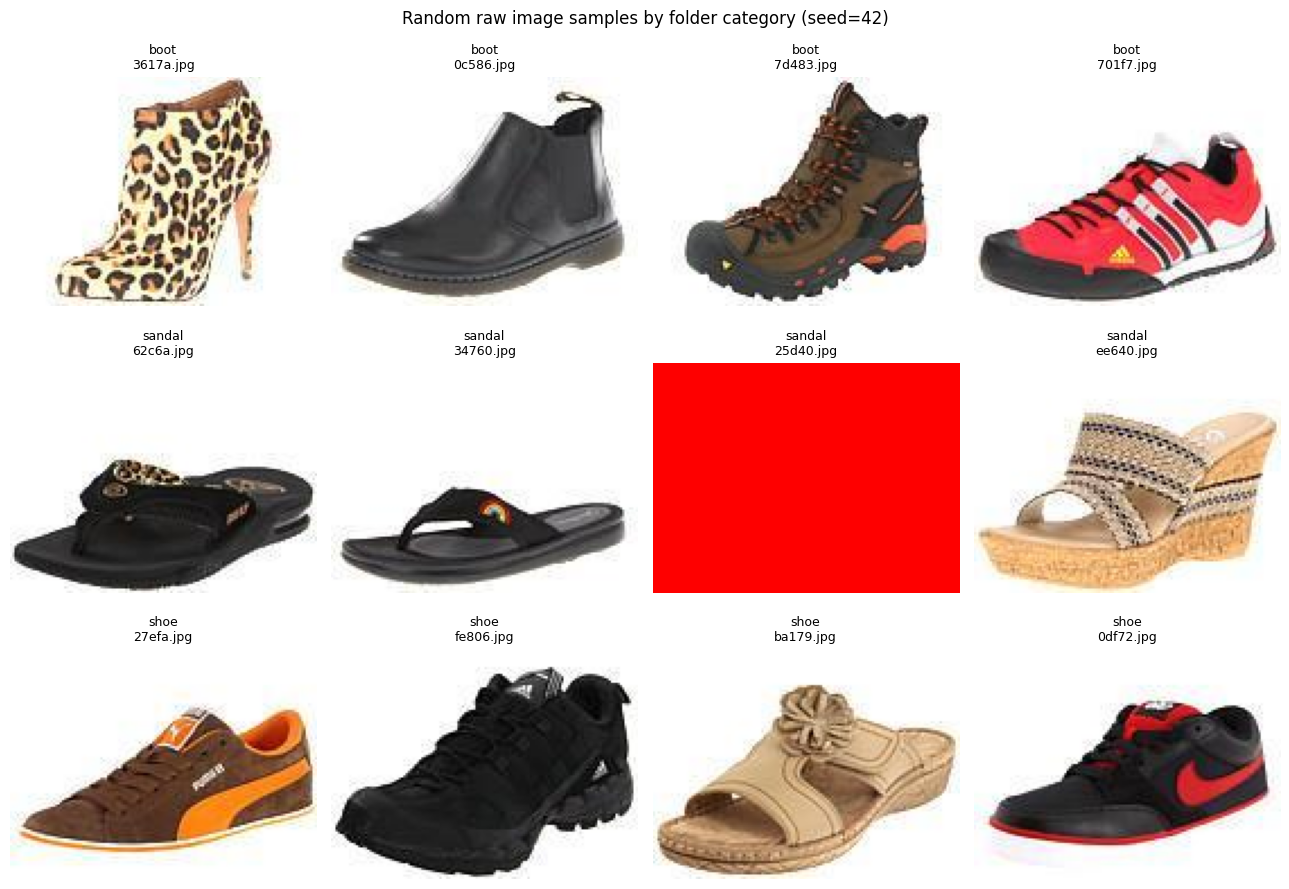

In [4]:
categories = sorted(raw_df['category'].unique())
fig, axes = plt.subplots(len(categories), 4, figsize=(13, 3.1 * len(categories)), squeeze=False)
for row, label in enumerate(categories):
    choices = raw_df.loc[raw_df['category'].eq(label), 'image_path'].tolist()
    picks = random.sample(choices, k=min(4, len(choices)))
    for col, ax in enumerate(axes[row]):
        ax.axis('off')
        if col < len(picks):
            with Image.open(ROOT / picks[col]) as image:
                ax.imshow(image.convert('RGB'))
            ax.set_title(f'{label}\n{Path(picks[col]).name}', fontsize=9)
plt.suptitle('Random raw image samples by folder category (seed=42)')
plt.tight_layout()
plt.show()

## 4. Category Distribution - Phân bố nhãn (từ thư mục ảnh thô)
Thống kê dùng tên thư mục cha làm category; điều này chỉ đúng nếu bộ dữ liệu tổ chức theo nhãn.

,images,percent
category,,
boot,305,33.55
sandal,301,33.11
shoe,303,33.33


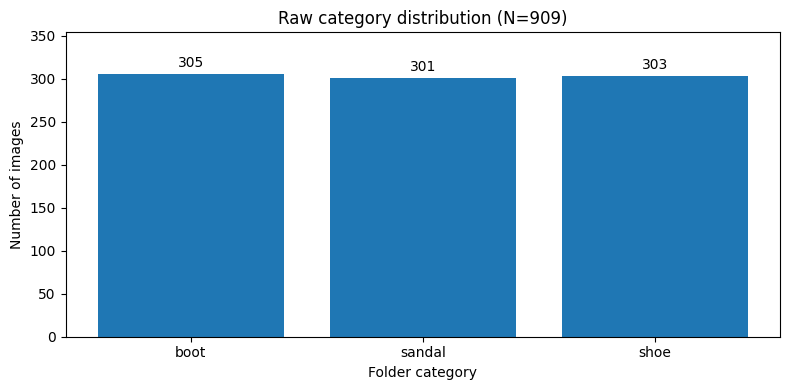

In [5]:
counts = raw_df['category'].value_counts().sort_index()
display(pd.DataFrame({'images': counts, 'percent': (100*counts/len(raw_df)).round(2)}))
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values)
ax.bar_label(bars, padding=3)
ax.set_ylim(0, max(counts)*1.16)
ax.set_xlabel('Folder category')
ax.set_ylabel('Number of images')
ax.set_title(f'Raw category distribution (N={len(raw_df)})')
plt.tight_layout()
plt.show()

## 5. Data Quality
Kiểm tra đường dẫn trùng nhau, ảnh có kích thước không hợp lệ, và file trùng **nội dung nhị phân** (SHA-256). File khác byte vẫn có thể trông giống nhau.

In [6]:
print('Đường dẫn trùng:', int(raw_df['image_path'].duplicated().sum()))
print('Kích thước không hợp lệ:', int(((raw_df['width']<=0)|(raw_df['height']<=0)).sum()))
print('Ảnh không đọc được:', len(errors))

hash_groups = {}
for path in raw_images:
    digest = sha256(path.read_bytes()).hexdigest()
    hash_groups.setdefault(digest, []).append(path.relative_to(ROOT).as_posix())
duplicates = [paths for paths in hash_groups.values() if len(paths)>1]
print('Nhóm file trùng byte-for-byte:', len(duplicates))
print('Số file dư do trùng byte:', sum(len(g)-1 for g in duplicates))
for group in duplicates[:5]:
    print(group)


Đường dẫn trùng: 0
Kích thước không hợp lệ: 0
Ảnh không đọc được: 0
Nhóm file trùng byte-for-byte: 0
Số file dư do trùng byte: 0


## 6. Processed Data
So sánh dữ liệu thô với `catalog.csv`

CSV là đầu ra của `prepare_dataset.py`; nó không chứa toàn bộ pixel ảnh, mà lưu đường dẫn, nhãn và kích thước để liên kết với embeddings.

In [7]:
if not CATALOG.is_file():
    raise FileNotFoundError('Thiếu catalog.csv — chạy python scripts/prepare_dataset.py trước.')
catalog = pd.read_csv(CATALOG)
required = {'image_id','image_path','category','width','height'}
if not required.issubset(catalog.columns):
    raise ValueError(f'CSV thiếu cột: {sorted(required-set(catalog.columns))}')
print('Total records:', len(catalog))
print('Images per category:')
print(catalog['category'].value_counts().sort_index().to_string())
print('Sample records:')
display(catalog.head(5))
print('ID trùng:', int(catalog['image_id'].duplicated().sum()))
print('Đường dẫn CSV trùng:', int(catalog['image_path'].duplicated().sum()))
print('Đường dẫn CSV không tồn tại:', sum(not (ROOT / str(p)).is_file() for p in catalog['image_path']))
raw_paths = set(raw_df['image_path'])
csv_paths = set(catalog['image_path'])
print('Ảnh hợp lệ có trong raw nhưng thiếu trong catalog:', len(raw_paths-csv_paths))
print('Đường dẫn có trong catalog nhưng không hợp lệ ở raw:', len(csv_paths-raw_paths))
merged = catalog.merge(raw_df, on='image_path', how='inner', suffixes=('_csv', '_raw'))
for col in ['category','width','height']:
    mismatches = int((merged[f'{col}_csv'].astype(str) != merged[f'{col}_raw'].astype(str)).sum())
    print(f'{col} metadata mismatch:', mismatches)

Total records: 909
Images per category:
category
boot      305
sandal    301
shoe      303
Sample records:


,image_id,image_path,category,width,height
0,0,data/raw/test-zip/boot/00980.jpg,boot,136,102
1,1,data/raw/test-zip/boot/00d04.jpg,boot,136,102
2,2,data/raw/test-zip/boot/01a4f.jpg,boot,136,102
3,3,data/raw/test-zip/boot/02677.jpg,boot,136,102
4,4,data/raw/test-zip/boot/037f2.jpg,boot,136,102


ID trùng: 0
Đường dẫn CSV trùng: 0
Đường dẫn CSV không tồn tại: 0
Ảnh hợp lệ có trong raw nhưng thiếu trong catalog: 0
Đường dẫn có trong catalog nhưng không hợp lệ ở raw: 0
category metadata mismatch: 0
width metadata mismatch: 0
height metadata mismatch: 0


## 7. Findings
- **Raw:** ảnh được giải nén từ `footwear-demo.zip` vào `data/raw/`, tổ chức theo thư mục (ví dụ `test-zip/boot/`).
- **Processed:** `prepare_dataset.py` đọc và xác thực ảnh, rồi ghi `data/processed/catalog.csv`.
- **Tiếp theo:** `build_index.py` đọc CSV theo thứ tự hàng để tạo `artifacts/clip_embeddings.npy`. Số hàng embeddings phải bằng số hàng CSV.
- Các thống kê bên trên phản ánh file hiện có khi chạy notebook; không tự động cập nhật khi bạn thêm/xóa ảnh.
- Kiểm tra thủ công ảnh và nhãn vẫn cần thiết; hash chỉ tìm file trùng byte, không kiểm tra ảnh trùng về nội dung thị giác.

**Cách dùng:** Chọn *Run All*. Để xem lại sau, lưu notebook với outputs trong VS Code. Notebook không ghi lại dữ liệu nguồn.